# 📊 Data Analyst Job Market Analysis

### Author
**Kaushik Sahu**  
B.Tech — Biomedical Engineering  
National Institute of Technology (NIT) Rourkela

## Project Overview

This project analyzes **1500+ Data Analyst job postings** collected from multiple online hiring platforms to uncover:

- Most in-demand technical skills
- Hiring trends across cities
- Experience-level distribution
- Salary patterns
- Skill co-occurrence trends

The project uses **Python, Pandas, NLP-style skill extraction, and data visualization techniques** to transform raw job descriptions into actionable hiring insights.

---

## 🛠️ Tools & Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Regex / Text Processing
- Jupyter Notebook

---

# 1️⃣ Importing Libraries & Loading Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings("ignore")

# Theme
plt.style.use("dark_background")
sns.set_style("dark")

# Load dataset
df = pd.read_csv("../data/kaggle_jobs.csv")

print("Dataset loaded successfully!")

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nSample:")
display(df.head())

Dataset loaded successfully!

Shape:
(1561, 16)

Columns:
['Unnamed: 0', 'job_title', 'company', 'experience', 'min exp', 'max exp', 'salary', 'base salary', 'max salary', 'location', 'jobListed(days ago)', 'postedIn', 'rating', 'reviews count', 'details', 'salary data provide by']

Sample:


,Unnamed: 0,job_title,company,experience,min exp,max exp,salary,base salary,max salary,location,jobListed(days ago),postedIn,rating,reviews count,details,salary data provide by
0,0,JP Morgan Chase - Client Data Analyst (4-8 yrs),JP Morgan Chase,4-8 Yrs,4.0,8.0,NaN,NaN,NaN,Hyderabad / Secunderabad,3.0,iimjobs,4.1,5300.0,"Banking, KYC, Banking Operations",NaN
1,1,Data Analyst - Bangalore,Schneider Electric,5-10 Yrs,5.0,10.0,₹ 8 - 16L/yr,800000.0,1600000.0,"Bangalore / Bengaluru, Bangalore Rural",4.0,Naukri,4.2,3500.0,"ERP, SAP, Data Analysis",Salary Listed by Company
2,2,Senior IT ATLAS Data Analyst and Integration S...,SAP Labs India Pvt. Ltd.,7-11 Yrs,7.0,11.0,NaN,NaN,NaN,Bangalore / Bengaluru,7.0,Naukri,4.3,1500.0,"data quality, Data analysis, quality management",NaN
3,3,Consultant Data Analyst,Pfizer,2-6 Yrs,2.0,6.0,NaN,NaN,NaN,Mumbai,3.0,Naukri,4.1,1700.0,"Power Bi, Commercial Operations, Data Management",NaN
4,4,Senior Data Analyst - Retail Liabilities,IDFC FIRST Bank,5-10 Yrs,5.0,10.0,NaN,NaN,NaN,Mumbai,5.0,Naukri,4.5,2300.0,"Test strategy, Analytical, Manager Technology",NaN


# 2️⃣ Data Cleaning & Preprocessing

In [2]:
# DATA CLEANING


# Create copy
jobs = df.copy()

# Drop unnecessary column
jobs.drop(columns=["Unnamed: 0"], inplace=True)

# Rename columns
jobs.rename(columns={
    "job_title": "Job Title",
    "company": "Company",
    "experience": "Experience",
    "min exp": "Min Experience",
    "max exp": "Max Experience",
    "salary": "Salary",
    "base salary": "Base Salary",
    "max salary": "Max Salary",
    "location": "Location",
    "jobListed(days ago)": "Days Ago",
    "postedIn": "Platform",
    "rating": "Rating",
    "reviews count": "Reviews",
    "details": "Details",
    "salary data provide by": "Salary Source"
}, inplace=True)

# Remove duplicates
before = len(jobs)

jobs.drop_duplicates(inplace=True)

after = len(jobs)

print(f"Duplicates removed: {before - after}")

# Missing values
print("\nMissing values:")
print(jobs.isnull().sum())

# Fill text nulls
text_cols = [
    "Salary",
    "Details",
    "Salary Source"
]

for col in text_cols:
    jobs[col] = jobs[col].fillna("Not Specified")

# Fill numeric nulls
numeric_cols = [
    "Base Salary",
    "Max Salary",
    "Rating",
    "Reviews",
    "Days Ago"
]

for col in numeric_cols:
    jobs[col] = jobs[col].fillna(0)

print("\nDataset cleaned successfully!")

print("\nFinal Shape:")
print(jobs.shape)

Duplicates removed: 71

Missing values:
Job Title            0
Company              0
Experience          34
Min Experience      34
Max Experience      34
Salary            1166
Base Salary       1166
Max Salary        1166
Location            33
Days Ago             0
Platform             0
Rating             398
Reviews            398
Details             33
Salary Source     1166
dtype: int64

Dataset cleaned successfully!

Final Shape:
(1490, 15)


# 3️⃣ Advanced Skill Extraction Engine

In [3]:
# ADVANCED SKILL EXTRACTION ENGINE

# Fill missing details
df["details"] = df["details"].fillna("").str.lower()

# MASTER SKILL LIST

SKILL_KEYWORDS = [

    # Core DA Skills
    "python",
    "sql",
    "excel",
    "power bi",
    "tableau",
    "statistics",
    "data analysis",
    "data visualization",

    # Python Ecosystem
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "tensorflow",
    "pytorch",

    # Databases
    "mysql",
    "postgresql",
    "mongodb",
    "oracle",

    # Cloud / Big Data
    "aws",
    "azure",
    "google cloud",
    "spark",
    "hadoop",

    # ML / AI
    "machine learning",
    "deep learning",
    "nlp",

    # Tools
    "git",
    "github",
    "jira",
    "sap",
    "erp",

    # Soft Skills
    "communication",
    "problem solving",
    "presentation",
    "powerpoint"
]

# SKILL EXTRACTION FUNCTION

def extract_skills(text):

    found_skills = []

    for skill in SKILL_KEYWORDS:

        if skill in text:
            found_skills.append(skill)

    return ", ".join(sorted(set(found_skills)))

# Create skills column
df["Skills"] = df["details"].apply(extract_skills)

print("Skills column created successfully!")

print("\nSample skills:")
print(df[["job_title", "Skills"]].head(10))

Skills column created successfully!

Sample skills:
                                           job_title                   Skills
0    JP Morgan Chase - Client Data Analyst (4-8 yrs)                         
1                           Data Analyst - Bangalore  data analysis, erp, sap
2  Senior IT ATLAS Data Analyst and Integration S...            data analysis
3                            Consultant Data Analyst                 power bi
4           Senior Data Analyst - Retail Liabilities                         
5    JP Morgan Chase - Client Data Analyst (4-9 yrs)                         
6                    Principal Business Data Analyst                         
7                               SENIOR, DATA ANALYST            data analysis
8             Data Analysts in Supply chain planning        power bi, tableau
9                                    Data Analyst CX                         


# 4️⃣ Feature Engineering

In [4]:
# CREATE BINARY SKILL COLUMNS

for skill in SKILL_KEYWORDS:

    col_name = (
        skill.replace(" ", "_")
             .replace("-", "_")
    )

    df[col_name] = df["Skills"].apply(
        lambda x: 1 if skill in x else 0
    )

print("Binary skill columns created!")

print("\nTotal skill columns:",
      len(SKILL_KEYWORDS))

# Preview
preview_cols = [
    "job_title",
    "python",
    "sql",
    "excel",
    "power_bi",
    "tableau",
    "machine_learning"
]

print(df[preview_cols].head(10))

Binary skill columns created!

Total skill columns: 36
                                           job_title  python  sql  excel  \
0    JP Morgan Chase - Client Data Analyst (4-8 yrs)       0    0      0   
1                           Data Analyst - Bangalore       0    0      0   
2  Senior IT ATLAS Data Analyst and Integration S...       0    0      0   
3                            Consultant Data Analyst       0    0      0   
4           Senior Data Analyst - Retail Liabilities       0    0      0   
5    JP Morgan Chase - Client Data Analyst (4-9 yrs)       0    0      0   
6                    Principal Business Data Analyst       0    0      0   
7                               SENIOR, DATA ANALYST       0    0      0   
8             Data Analysts in Supply chain planning       0    0      0   
9                                    Data Analyst CX       0    0      0   

   power_bi  tableau  machine_learning  
0         0        0                 0  
1         0        0      

In [5]:
# TOP SKILLS

skill_cols = [
    skill.replace(" ", "_").replace("-", "_")
    for skill in SKILL_KEYWORDS
]

top_skills = (
    df[skill_cols]
    .sum()
    .sort_values(ascending=False)
)

print(top_skills.head(20))

sql                   338
data_analysis         301
python                155
power_bi              135
excel                  93
tableau                71
data_visualization     52
sap                    25
machine_learning       23
mysql                  22
erp                    21
spark                  20
azure                  14
oracle                 12
communication          12
aws                    11
git                    10
statistics              8
presentation            4
postgresql              4
dtype: int64


# 5️⃣ Experience Level Classification

In [6]:
# EXPERIENCE LEVEL CLEANING

def classify_experience(x):

    if pd.isna(x):
        return "Not Specified"

    x = str(x).lower()

    if "0" in x or "fresher" in x:
        return "Fresher"

    elif "1" in x or "2" in x:
        return "Junior"

    elif "3" in x or "4" in x or "5" in x:
        return "Mid"

    else:
        return "Senior"

df["Experience Level"] = df["experience"].apply(classify_experience)

print(df["Experience Level"].value_counts())

Experience Level
Junior           686
Mid              532
Fresher          272
Senior            37
Not Specified     34
Name: count, dtype: int64


In [7]:
# LOCATION CLEANING

df["location"] = (
    df["location"]
    .fillna("Unknown")
    .str.split("/")
    .str[0]
    .str.strip()
)

print(df["location"].value_counts().head(10))

location
Bangalore    364
Mumbai       165
Hyderabad    139
Gurgaon      121
Pune          90
Chennai       81
Remote        55
Noida         42
New Delhi     40
Unknown       33
Name: count, dtype: int64


In [8]:
# COMPANY NAME CLEANING

company_replacements = {
    'HuQuo Consulting Pvt. Ltd.'             : 'HuQuo Consulting',
    'Huquo'                                   : 'HuQuo Consulting',
    'RIGHT STEP CONSULTING PRIVATE LIMITED'   : 'Right Step Consulting',
    'Essenware Private Limted'                : 'Essenware Pvt. Ltd.',
    'Fusion Plus Solutions Inc'               : 'Fusion Plus Solutions',
    'Coders Brain Pvt Ltd'                    : 'Coders Brain',
    'D2N SOLUTIONS'                           : 'D2N Solutions',
}

df['company'] = df['company'].replace(company_replacements)

# Title case everything for consistency
df['company'] = df['company'].str.strip().str.title()

# Verify
print("Top 15 companies after cleaning:")
print(df['company'].value_counts().head(15))

Top 15 companies after cleaning:
company
Huquo Consulting                   26
Diverse Lynx                       24
Right Step Consulting              14
Coders Brain                       13
Essenware Pvt. Ltd.                11
Idfc First Bank                    10
Fusion Plus Solutions              10
Ixie Gaming                         9
D2N Solutions                       9
Xpheno                              9
Pradeepit                           8
Cotocus.Com                         8
Siemens Limited                     7
S&P Capital Iq (India) Pvt. Ltd     7
Indium Software (India) Limited     7
Name: count, dtype: int64


In [9]:
# SAVES CLEANED DATASET

import os

os.makedirs("../data", exist_ok=True)

df.to_csv("../data/cleaned_da_jobs.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [10]:
print(df.shape)

print(df[[
    "job_title",
    "company",
    "location",
    "Experience Level",
    "Skills"
]].head())

(1561, 54)
                                           job_title  \
0    JP Morgan Chase - Client Data Analyst (4-8 yrs)   
1                           Data Analyst - Bangalore   
2  Senior IT ATLAS Data Analyst and Integration S...   
3                            Consultant Data Analyst   
4           Senior Data Analyst - Retail Liabilities   

                    company   location Experience Level  \
0           Jp Morgan Chase  Hyderabad              Mid   
1        Schneider Electric  Bangalore          Fresher   
2  Sap Labs India Pvt. Ltd.  Bangalore           Junior   
3                    Pfizer     Mumbai           Junior   
4           Idfc First Bank     Mumbai          Fresher   

                    Skills  
0                           
1  data analysis, erp, sap  
2            data analysis  
3                 power bi  
4                           


In [11]:
# GLOBAL CHART THEME

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import numpy as np
import os

os.makedirs("../visuals", exist_ok=True)

BG       = "#0A0E1A"
AX       = "#111827"
TEXT     = "#F0F4FF"
MUTED    = "#8892A4"
GRID     = "#253047"
BLUE     = "#3B82F6"
GREEN    = "#10B981"
AMBER    = "#F59E0B"
RED      = "#EF4444"
PURPLE   = "#8B5CF6"

plt.rcParams.update({
    "figure.facecolor":  BG,
    "axes.facecolor":    AX,
    "axes.edgecolor":    MUTED,
    "axes.labelcolor":   TEXT,
    "axes.titlecolor":   TEXT,
    "text.color":        TEXT,
    "xtick.color":       TEXT,
    "ytick.color":       TEXT,
    "grid.color":        GRID,
    "grid.linewidth":    0.5,
    "font.family":       "DejaVu Sans",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "savefig.facecolor": BG,
    "savefig.dpi":       150,
})

df = pd.read_csv("../data/cleaned_da_jobs.csv")
print(f"Dataset loaded: {df.shape[0]:,} jobs | {df.shape[1]} columns")

Dataset loaded: 1,561 jobs | 54 columns


# 6️⃣ Top In-Demand Skills

## Key Question

Which technical skills appear most frequently in Data Analyst job postings?

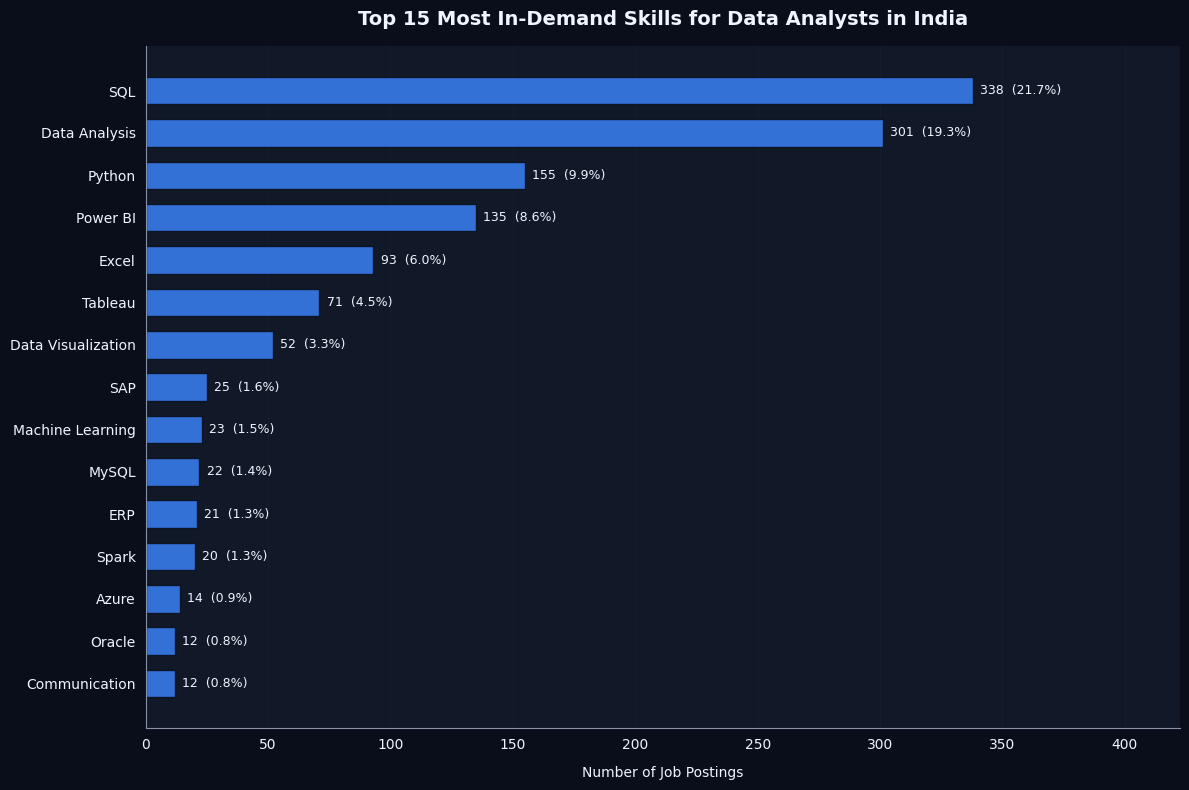

Chart 1 saved


In [12]:
# CHART 1 — Top 15 In-Demand Skills

skill_cols = [
    'python','sql','excel','power_bi','tableau','statistics',
    'data_analysis','data_visualization','pandas','numpy',
    'matplotlib','seaborn','scikit_learn','tensorflow','pytorch',
    'mysql','postgresql','mongodb','oracle','aws','azure',
    'google_cloud','spark','hadoop','machine_learning',
    'deep_learning','nlp','git','github','jira','sap','erp',
    'communication','problem_solving','presentation','powerpoint'
]

# Friendly display names
name_map = {
    'sql':'SQL', 'python':'Python', 'excel':'Excel',
    'power_bi':'Power BI', 'tableau':'Tableau',
    'data_analysis':'Data Analysis', 'machine_learning':'Machine Learning',
    'data_visualization':'Data Visualization', 'sap':'SAP',
    'mysql':'MySQL', 'erp':'ERP', 'spark':'Spark',
    'azure':'Azure', 'aws':'AWS', 'oracle':'Oracle',
    'communication':'Communication', 'git':'Git',
    'statistics':'Statistics', 'pandas':'Pandas',
    'scikit_learn':'Scikit-Learn', 'numpy':'NumPy',
    'postgresql':'PostgreSQL', 'mongodb':'MongoDB',
    'presentation':'Presentation', 'powerpoint':'PowerPoint',
    'github':'GitHub', 'jira':'Jira', 'tensorflow':'TensorFlow',
    'pytorch':'PyTorch', 'google_cloud':'Google Cloud',
    'hadoop':'Hadoop', 'deep_learning':'Deep Learning',
    'nlp':'NLP', 'matplotlib':'Matplotlib', 'seaborn':'Seaborn',
    'problem_solving':'Problem Solving'
}

skill_freq = (df[skill_cols].sum()
                .sort_values(ascending=False)
                .head(15))
skill_freq.index = [name_map.get(i, i) for i in skill_freq.index]
total = len(df)

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(skill_freq.index[::-1],
               skill_freq.values[::-1],
               color=BLUE, alpha=0.85, edgecolor=BG, height=0.65)

for bar, val in zip(bars, skill_freq.values[::-1]):
    pct = val / total * 100
    ax.text(val + 3, bar.get_y() + bar.get_height()/2,
            f"{val:,}  ({pct:.1f}%)",
            va='center', fontsize=9, color=TEXT)

ax.set_xlabel("Number of Job Postings", labelpad=10)
ax.set_title("Top 15 Most In-Demand Skills for Data Analysts in India",
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0, skill_freq.max() * 1.25)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig("../visuals/01_top_skills.png", bbox_inches='tight')
plt.show()
print("Chart 1 saved")

# 7️⃣ Top Hiring Cities

## Key Question

Which cities currently offer the highest number of Data Analyst opportunities?

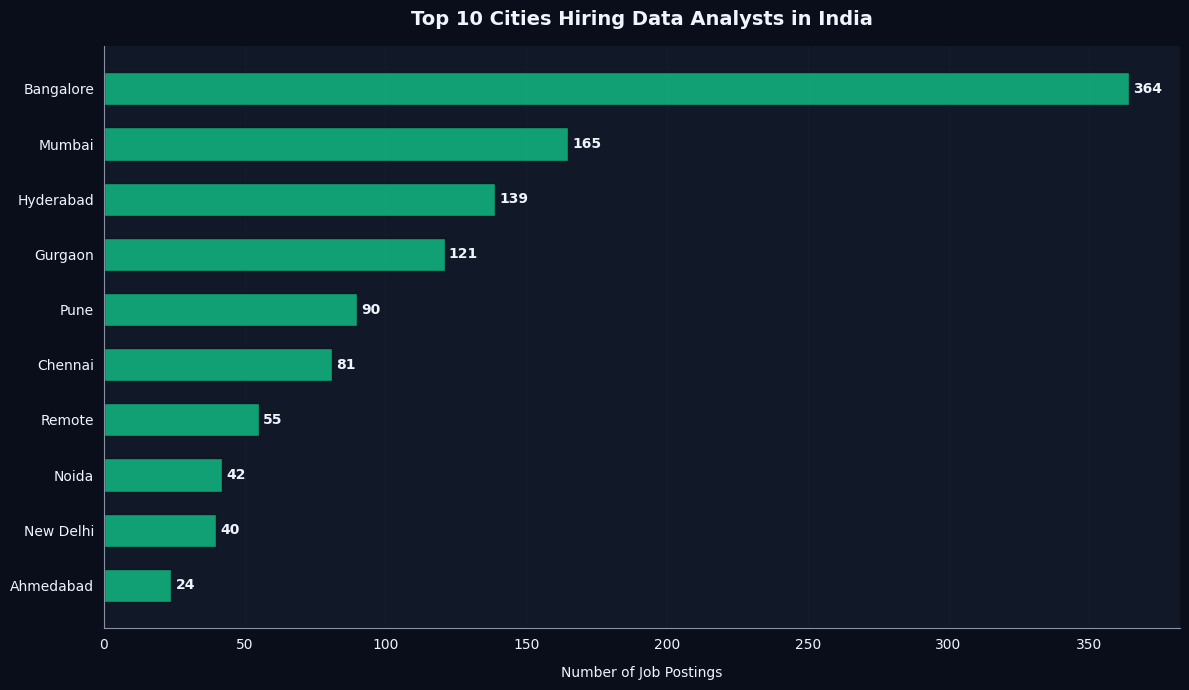

Chart 2 saved


In [13]:
# CHART 2 — Top 10 Hiring Cities

# Clean multi-city entries and unknown
city_clean = df['location'].copy()
city_clean = city_clean[~city_clean.str.contains(
    r'\+\d+\s*more|Unknown|,', na=False, regex=True
)]
city_counts = city_clean.value_counts().head(10)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(city_counts.index[::-1],
               city_counts.values[::-1],
               color=GREEN, alpha=0.85, edgecolor=BG, height=0.6)

for bar, val in zip(bars, city_counts.values[::-1]):
    ax.text(val + 1.5, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=10,
            fontweight='bold', color=TEXT)

ax.set_xlabel("Number of Job Postings", labelpad=10)
ax.set_title("Top 10 Cities Hiring Data Analysts in India",
             fontsize=14, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig("../visuals/02_top_cities.png", bbox_inches='tight')
plt.show()
print("Chart 2 saved")

# 8️⃣ Experience-Level Distribution

## Key Question

What experience levels are companies hiring for most frequently?

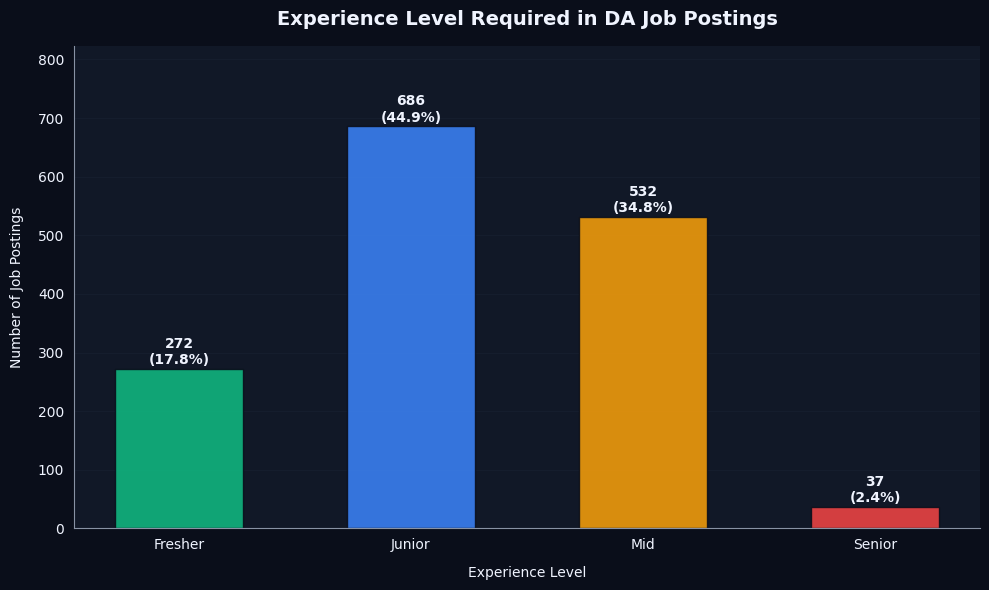

Chart 3 saved


In [14]:
# CHART 3 — Experience Level Distribution

exp_order  = ['Fresher', 'Junior', 'Mid', 'Senior']
exp_colors = [GREEN, BLUE, AMBER, RED]
exp_counts = (df[df['Experience Level'].isin(exp_order)]
              ['Experience Level']
              .value_counts()
              .reindex(exp_order))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(exp_counts.index, exp_counts.values,
              color=exp_colors, edgecolor=BG,
              width=0.55, alpha=0.88)

total_exp = exp_counts.sum()
for bar, val in zip(bars, exp_counts.values):
    pct = val / total_exp * 100
    ax.text(bar.get_x() + bar.get_width()/2,
            val + 8,
            f"{val}\n({pct:.1f}%)",
            ha='center', fontsize=10,
            fontweight='bold', color=TEXT)

ax.set_ylabel("Number of Job Postings", labelpad=10)
ax.set_xlabel("Experience Level", labelpad=10)
ax.set_title("Experience Level Required in DA Job Postings",
             fontsize=14, fontweight='bold', pad=15)
ax.set_ylim(0, exp_counts.max() * 1.2)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("../visuals/03_experience_distribution.png",
            bbox_inches='tight')
plt.show()
print("Chart 3 saved")

# 9️⃣ Salary Distribution Analysis

## Key Question

What salary ranges are commonly offered for Data Analyst positions?

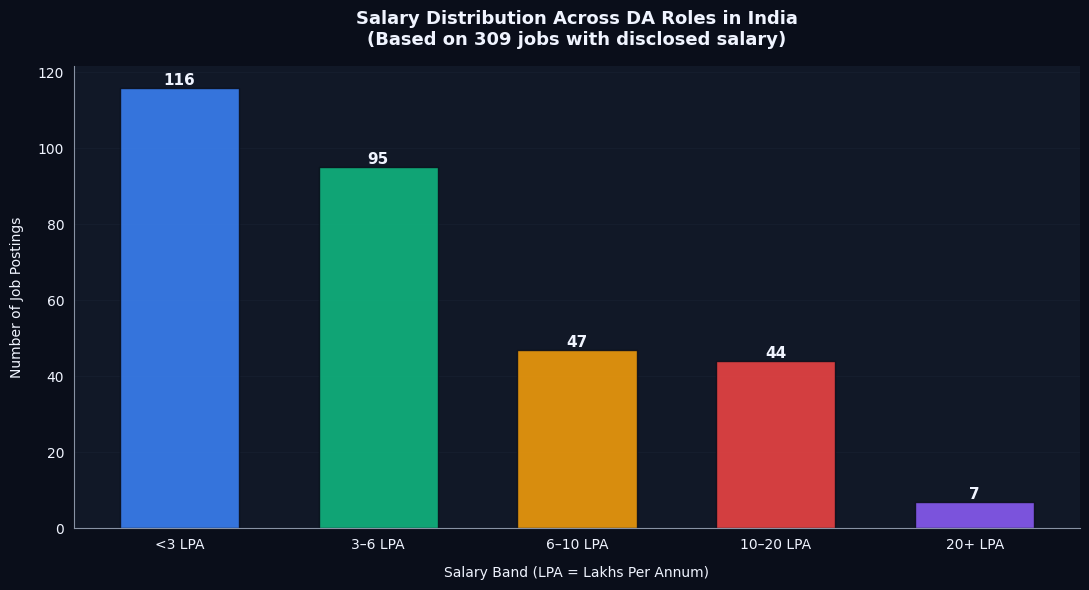

Chart 4 saved


In [15]:
# CHART 4 — Salary Distribution (INR)

salary_df = df[df['base salary'].notna() &
               (df['base salary'] > 50000)].copy()
salary_df['Salary (LPA)'] = salary_df['base salary'] / 100000

bins   = [0, 3, 6, 10, 20, 100]
labels = ['<3 LPA', '3–6 LPA', '6–10 LPA', '10–20 LPA', '20+ LPA']
colors_s = [BLUE, GREEN, AMBER, RED, PURPLE]
salary_df['Salary Band'] = pd.cut(
    salary_df['Salary (LPA)'],
    bins=bins, labels=labels, right=True
)
band_counts = salary_df['Salary Band'].value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(band_counts.index, band_counts.values,
              color=colors_s, edgecolor=BG,
              width=0.6, alpha=0.88)

for bar, val in zip(bars, band_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            val + 0.8,
            str(val), ha='center',
            fontsize=11, fontweight='bold', color=TEXT)

ax.set_ylabel("Number of Job Postings", labelpad=10)
ax.set_xlabel("Salary Band (LPA = Lakhs Per Annum)", labelpad=10)
ax.set_title("Salary Distribution Across DA Roles in India\n"
             f"(Based on {len(salary_df):,} jobs with disclosed salary)",
             fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("../visuals/04_salary_distribution.png",
            bbox_inches='tight')
plt.show()
print("Chart 4 saved")

# 1️⃣0️⃣ Top Hiring Companies

## Key Question

Which companies are actively hiring Data Analysts?

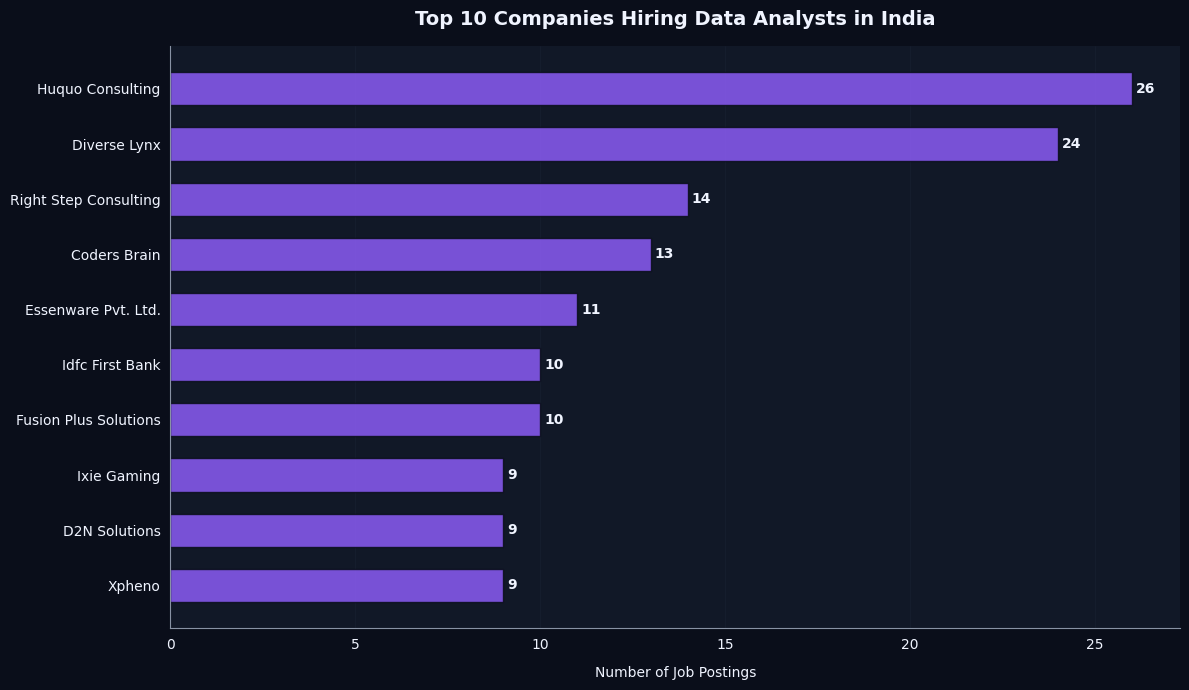

Chart 5 saved


In [16]:
# CHART 5 — Top 10 Hiring Companies

company_counts = df['company'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(company_counts.index[::-1],
               company_counts.values[::-1],
               color=PURPLE, alpha=0.85,
               edgecolor=BG, height=0.6)

for bar, val in zip(bars, company_counts.values[::-1]):
    ax.text(val + 0.1, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=10,
            fontweight='bold', color=TEXT)

ax.set_xlabel("Number of Job Postings", labelpad=10)
ax.set_title("Top 10 Companies Hiring Data Analysts in India",
             fontsize=14, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig("../visuals/05_top_companies.png", bbox_inches='tight')
plt.show()
print("Chart 5 saved")

# 1️⃣1️⃣ Skill Co-occurrence Analysis

## Key Question

Which technical skills are commonly required together in Data Analyst roles?

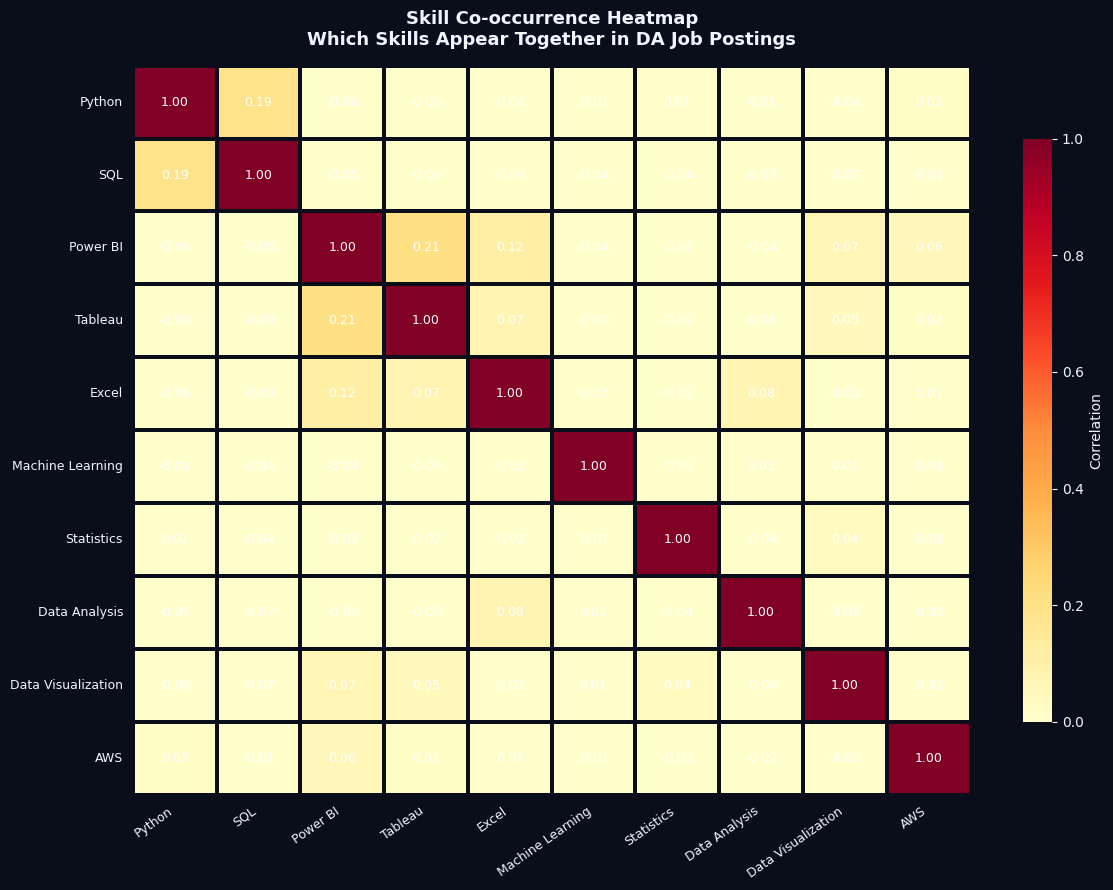

Chart 6 saved


In [17]:
# CHART 6 — Skill Co-occurrence Heatmap

top_skills_heatmap = [
    'python','sql','power_bi','tableau','excel',
    'machine_learning','statistics','data_analysis',
    'data_visualization','aws'
]

heatmap_labels = [name_map.get(s, s) for s in top_skills_heatmap]
corr = df[top_skills_heatmap].corr()
corr.index   = heatmap_labels
corr.columns = heatmap_labels

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    corr, ax=ax,
    cmap='YlOrRd',
    vmin=0,
    vmax=1,
    annot=True, fmt='.2f',
    annot_kws={'size': 9, 'color': 'white'},
    linewidths=1.5, linecolor=BG,
    cbar_kws={'label': 'Correlation', 'shrink': 0.8}
)
ax.set_title("Skill Co-occurrence Heatmap\n"
             "Which Skills Appear Together in DA Job Postings",
             fontsize=13, fontweight='bold', pad=15)
ax.set_xticklabels(ax.get_xticklabels(),
                   rotation=35, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig("../visuals/06_skill_heatmap.png", bbox_inches='tight')
plt.show()
print("Chart 6 saved")

# 1️⃣2️⃣ Key Insights & Findings

## Major Insights

### 1. SQL remains the most in-demand skill
SQL appeared more frequently than Python, indicating strong demand for data querying and database analysis capabilities.

---

### 2. Business Intelligence tools are highly valued
Power BI and Tableau consistently appeared across job postings, highlighting the importance of dashboarding and reporting skills.

---

### 3. Junior-level hiring dominates the market
Most openings were targeted at Junior and Mid-level professionals, suggesting strong entry-level demand.

---

### 4. Bangalore remains a major hiring hub
Bangalore showed one of the highest concentrations of Data Analyst openings among all cities analyzed.

---

### 5. Technical + Communication skills are both important
Alongside technical tools, employers also emphasized communication and presentation abilities.

# ✅ Final Conclusion

This project demonstrates how raw job posting data can be transformed into actionable labor-market insights using Python-based data analytics techniques.

The analysis highlights current trends in:

- Technical skill demand
- Experience requirements
- Hiring geography
- Salary distribution
- Skill relationships

The project also demonstrates practical applications of:

- Data Cleaning
- Text Processing
- Feature Engineering
- Exploratory Data Analysis
- Data Visualization

---

## Final Outcome

By analyzing 1500+ job postings, this project provides a data-driven overview of the current Data Analyst hiring landscape and the skills most valued by employers.